In [1]:
import warnings

with warnings.catch_warnings():
    warnings.simplefilter(action="ignore", category=FutureWarning)
    import os, math
    from pathlib import Path
    import scanpy as sc
    import numpy as np
    import seaborn as sns
    import pandas as pd
    import matplotlib as mpl
    import matplotlib.pyplot as plt
    from tqdm import tqdm
    from scipy import stats
    from scipy.stats import pearsonr, spearmanr
    from scipy.sparse import issparse

pd.set_option("display.max_rows", 500)
pd.set_option("display.max_columns", None)

os.chdir(".././")
!pwd

../.


In [2]:
%load_ext autoreload
%autoreload 1

%aimport s7_helpers
import s7_helpers

In [3]:
# plt.rcParams["figure.dpi"] = 80

### Analyze corr metrics

In [5]:
corr_df = pd.read_csv(
    ".././5.1_2_level_corr_stats.csv",
    index_col=0,
)
corr_df.head(1)

,Tissue_global,cell_type,pearson_r,pearson_p,spearman_r,spearman_p,n_donors,pearson_fdr,spearman_fdr,method,level
0,Colon,B cells,0.5263,0.036238,0.493373,0.052132,16,0.119057,0.217114,sp,ct


In [6]:
corr_df.head()

,Tissue_global,cell_type,pearson_r,pearson_p,spearman_r,spearman_p,n_donors,pearson_fdr,spearman_fdr,method,level
0,Colon,B cells,0.526300,0.036238,0.493373,0.052132,16,0.119057,0.217114,sp,ct
1,Colon,CD4 T cells,0.209416,0.337556,0.202820,0.353333,23,0.475815,0.578328,sp,ct
2,Colon,Crypt stem cells,0.036195,0.883049,-0.121266,0.620931,19,0.901837,0.805532,sp,ct
3,Colon,Enterocytes,0.437118,0.032687,0.426116,0.037870,24,0.119057,0.217114,sp,ct
4,Colon,Fibroblasts,0.554372,0.011194,0.623730,0.003295,20,0.094523,0.039545,sp,ct


In [7]:
"""all metrics"""


def calculate_summary(group, corr):
    """Summary function"""
    rho = group[f"{corr}_r"].dropna()
    n = len(rho)
    q1 = rho.quantile(0.25)
    median = rho.median()
    q3 = rho.quantile(0.75)

    return pd.Series(
        {
            # Number of tests
            f"n_tests": n,
            # Central tendency / effect size
            f"median_{corr}_r": median,
            # f"mean_{corr}_r": rho.mean(),
            # Directional consistency
            f"n_pos_{corr}": (rho > 0).sum(),
            f"percent_pos_{corr}": (rho > 0).mean() * 100,
            # Significant positive associations
            f"n_pos_FDR05_{corr}": (
                (group[f"{corr}_r"] > 0) & (group[f"{corr}_fdr"] < FDR_THRESHOLD)
            ).sum(),
            f"percent_pos_FDR05_{corr}": (
                (group[f"{corr}_r"] > 0) & (group[f"{corr}_fdr"] < FDR_THRESHOLD)
            ).mean()
            * 100,
            # Heterogeneity
            f"q1_{corr}": q1,
            f"q3_{corr}": q3,
            f"IQR_{corr}": q3 - q1,
            f"std_{corr}": rho.std(),
            # Additional information
            # f"min_r_{corr}": rho.min(), f"max_r_{corr}": rho.max(),
        }
    )


FDR_THRESHOLD = 0.05

metrics_dfs = []
for corr in "pearson", "spearman":
    df = corr_df.copy()
    df = df.dropna(subset=[f"{corr}_r"])

    # Булевы признаки
    df[f"positive_{corr}"] = df[f"{corr}_r"] > 0
    df[f"positive_signif_{corr}"] = (df[f"{corr}_r"] > 0) & (
        df[f"{corr}_fdr"] < FDR_THRESHOLD
    )

    # ============================================================
    # Calculate Method × Level statistics
    # ============================================================

    metrics_df = (
        df.groupby(["method", "level"], observed=True)
        .apply(lambda group: calculate_summary(group, corr), include_groups=False)
        .reset_index()
    )

    metrics_dfs.append(metrics_df)

In [8]:
order = [
    "method",
    "level",
    "n_tests",
    "median_pearson_r",
    "median_spearman_r",
    "n_pos_pearson",
    "n_pos_spearman",
    "percent_pos_pearson",
    "percent_pos_spearman",
    "n_pos_FDR05_pearson",
    "n_pos_FDR05_spearman",
    "percent_pos_FDR05_pearson",
    "percent_pos_FDR05_spearman",
    "q1_pearson",
    "q1_spearman",
    "q3_pearson",
    "q3_spearman",
    "IQR_pearson",
    "IQR_spearman",
    "std_pearson",
    "std_spearman",
]

metrics_df = pd.concat(metrics_dfs, axis=1)
metrics_df = metrics_df[order]
metrics_df = metrics_df.loc[:, ~metrics_df.columns.duplicated()]
metrics_df

,method,level,n_tests,median_pearson_r,median_spearman_r,n_pos_pearson,n_pos_spearman,percent_pos_pearson,percent_pos_spearman,n_pos_FDR05_pearson,n_pos_FDR05_spearman,percent_pos_FDR05_pearson,percent_pos_FDR05_spearman,q1_pearson,q1_spearman,q3_pearson,q3_spearman,IQR_pearson,IQR_spearman,std_pearson,std_spearman
0,ds,ct,69.0,0.016999,0.000000,37.0,33.0,53.623188,47.826087,0.0,0.0,0.00,0.000000,-0.207923,-0.185084,0.214060,0.189759,0.421984,0.374843,0.382724,0.353581
1,ds,gse,69.0,0.031505,0.018019,37.0,35.0,53.623188,50.724638,0.0,0.0,0.00,0.000000,-0.176122,-0.175621,0.235637,0.222223,0.411759,0.397843,0.384750,0.369832
2,ds,gsm,69.0,0.082289,0.064749,41.0,40.0,59.420290,57.971014,0.0,0.0,0.00,0.000000,-0.182491,-0.202008,0.339201,0.259160,0.521692,0.461168,0.403783,0.413890
3,sid,ct,72.0,-0.115663,-0.057744,31.0,31.0,43.055556,43.055556,0.0,1.0,0.00,1.388889,-0.303592,-0.315485,0.154662,0.197215,0.458254,0.512700,0.374717,0.390626
4,sid,gse,72.0,-0.071526,0.040058,33.0,37.0,45.833333,51.388889,0.0,1.0,0.00,1.388889,-0.272026,-0.302474,0.181864,0.204151,0.453890,0.506625,0.392512,0.406892
5,sid,gsm,72.0,0.006464,0.000163,37.0,36.0,51.388889,50.000000,0.0,1.0,0.00,1.388889,-0.230630,-0.202846,0.230018,0.230579,0.460648,0.433426,0.417120,0.395760
6,sp,ct,48.0,0.464715,0.330723,48.0,45.0,100.000000,93.750000,3.0,4.0,6.25,8.333333,0.274772,0.157823,0.602876,0.524619,0.328104,0.366796,0.246933,0.271122
7,sp,gse,48.0,0.360712,0.313388,45.0,42.0,93.750000,87.500000,0.0,1.0,0.00,2.083333,0.283437,0.149399,0.546184,0.501223,0.262746,0.351824,0.289589,0.277508
8,sp,gsm,48.0,0.030702,0.007516,26.0,25.0,54.166667,52.083333,0.0,0.0,0.00,0.000000,-0.208179,-0.232861,0.237609,0.239129,0.445788,0.471990,0.380900,0.345640


In [9]:
rank_cols = [
    "median_pearson_r",
    "median_spearman_r",
    "n_pos_pearson",
    "n_pos_spearman",
    "percent_pos_pearson",
    "percent_pos_spearman",
    "n_pos_FDR05_pearson",
    "n_pos_FDR05_spearman",
    "percent_pos_FDR05_pearson",
    "percent_pos_FDR05_spearman",
]

id_cols = ["method", "level", "n_tests"]

# создаём новый DataFrame с идентифицирующими столбцами
rank_df = metrics_df[id_cols].copy()

# добавляем ранги для каждой метрики
rank_df[[f"{col}_rank" for col in rank_cols]] = metrics_df[rank_cols].rank(
    ascending=False, method="min"
)

# средний ранг
rank_df["mean_rank"] = rank_df[[f"{col}_rank" for col in rank_cols]].mean(axis=1)

rank_df = rank_df.sort_values("mean_rank").reset_index(drop=True)
rank_df

"""если то же самое посчитать только по спирмену, будет тот же самый итоговый порядок"""

'если то же самое посчитать только по спирмену, будет тот же самый итоговый порядок'

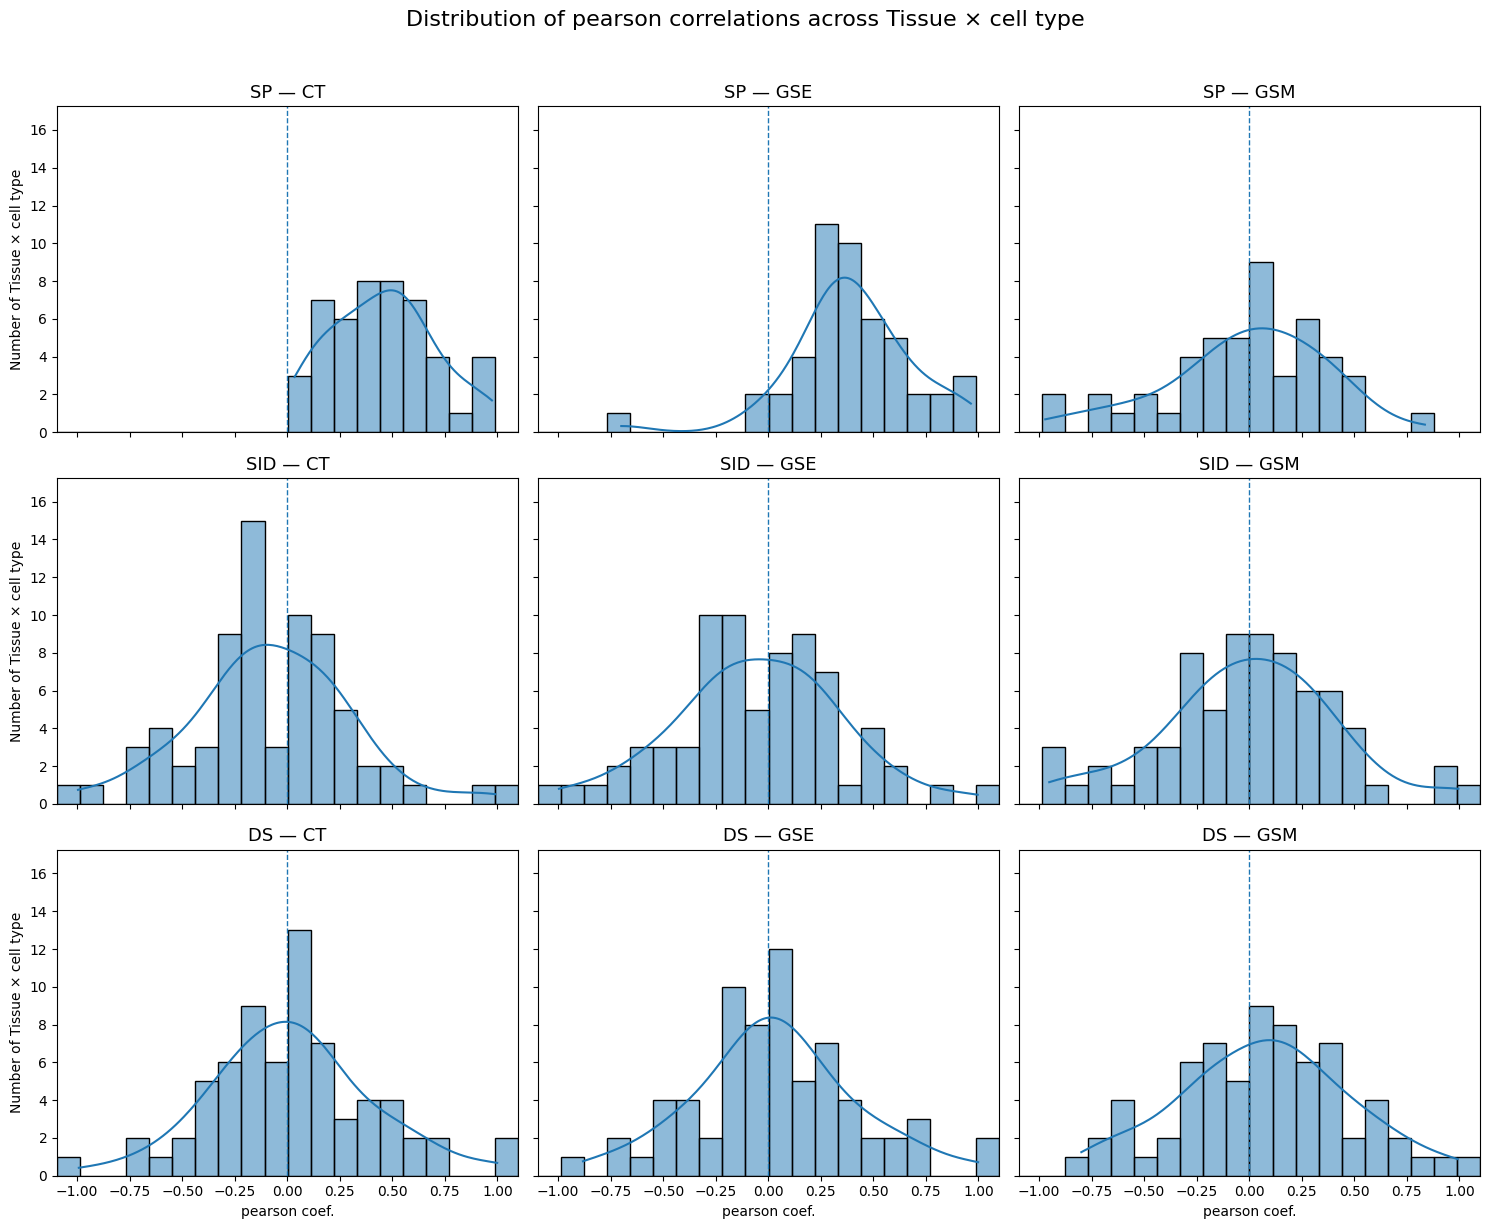

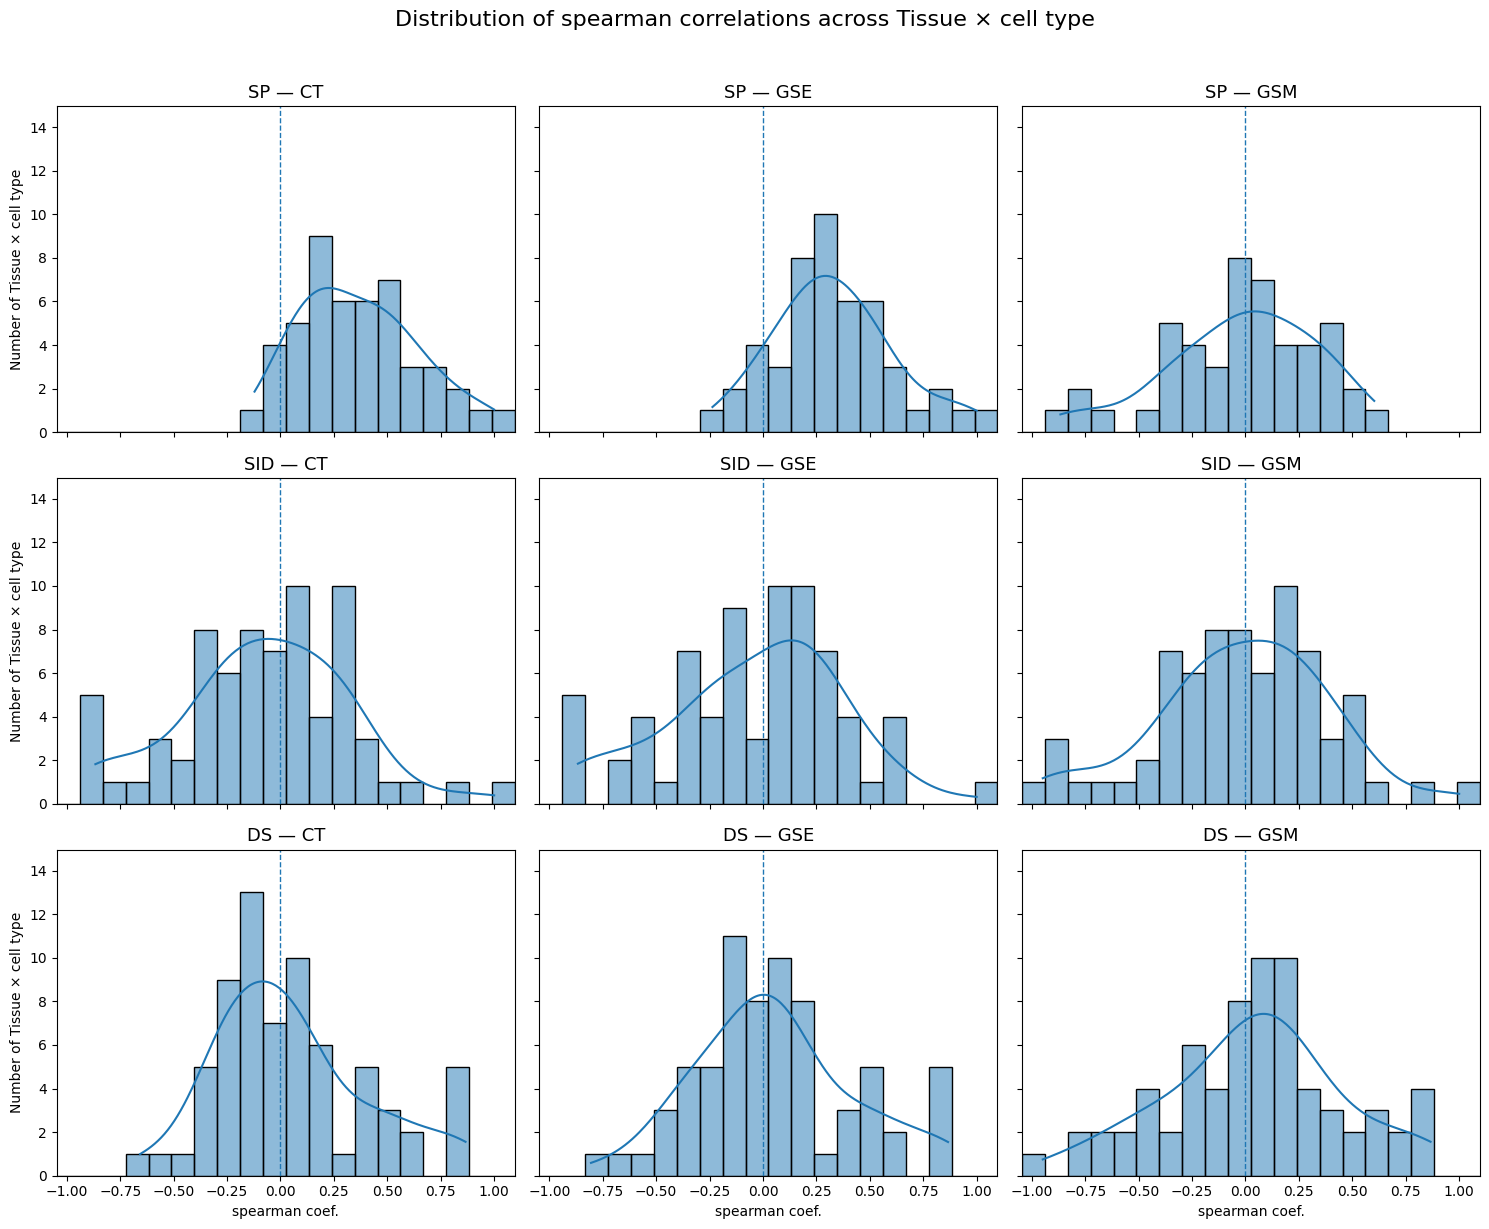

In [10]:
"""spearman rho distributions"""

method_order = ["sp", "sid", "ds"]
level_order = ["ct", "gse", "gsm"]

method_labels = {"sp": "sp", "sid": "sid", "ds": "ds"}
level_labels = {"ct": "CT", "gse": "GSE", "gsm": "GSM"}

for corr in "pearson", "spearman":
    plot_df = corr_df.dropna(subset=[f"{corr}_r"]).copy()
    # X: общий диапазон
    x_min = plot_df[f"{corr}_r"].min()
    x_max = plot_df[f"{corr}_r"].max()
    # Немного расширяем диапазон
    x_margin = 0.05 * (x_max - x_min)
    x_lim = (x_min - x_margin, x_max + x_margin)

    # Y: сначала определяем максимальную высоту histogram
    # при одинаковом количестве bins
    n_bins = 20
    max_count = 0

    for method in method_order:
        for level in level_order:
            values = plot_df.loc[
                (plot_df["method"] == method) & (plot_df["level"] == level), f"{corr}_r"
            ]
            counts, _ = np.histogram(values, bins=n_bins, range=x_lim)
            if len(counts) > 0:
                max_count = max(max_count, counts.max())

    y_lim = (0, max_count * 1.15)

    # Figure 3 × 3
    fig, axes = plt.subplots(
        nrows=3, ncols=3, figsize=(15, 12), sharex=True, sharey=True
    )

    for i, method in enumerate(method_order):
        for j, level in enumerate(level_order):
            ax = axes[i, j]
            values = plot_df.loc[
                (plot_df["method"] == method) & (plot_df["level"] == level), f"{corr}_r"
            ]

            # Histogram
            sns.histplot(
                values, bins=n_bins, binrange=x_lim, stat="count", kde=True, ax=ax
            )
            ax.axvline(0, linestyle="--", linewidth=1)  # Zero correlation line

            # Общие пределы
            ax.set_xlim(x_lim)
            ax.set_ylim(y_lim)

            ax.set_title(
                f"{method_labels[method]} — {level_labels[level]}", fontsize=13
            )

            # Подписи только по краям
            if i == 2:
                ax.set_xlabel(f"{corr} coef.")
            else:
                ax.set_xlabel("")

            if j == 0:
                ax.set_ylabel("Number of Tissue × cell type")
            else:
                ax.set_ylabel("")

    fig.suptitle(
        f"Distribution of {corr} correlations across Tissue × cell type",
        fontsize=16,
        y=1.02,
    )

    plt.tight_layout()

    # plt.savefig(
    #     "spearman_rho_distributions_3x3.png",
    #     dpi=300,
    #     bbox_inches="tight"
    # )

    plt.show()

### **primary binarization level** - уровень бинаризации Sc/NSc клеток при помощи GMM

см. график выше

критерий - наибольшее число положительных корреляций % сен клеток с возрастом. *Вне зависимости от уровня значимости* (тк предполагаем, что оч шумные данные, смотрим на направление)

если брать один уровень - пусть будет GSE, тк предполагается что в разных сериях мб разное покрытие как батч эффект. Распределения spearman rho у всех 3-х методов на этом уровне имеют медиану > 0

если оптимальный для каждого уровня метод - это будут:
- sp - ct
- ds - gsm
- sid - gse

### viz - spearman

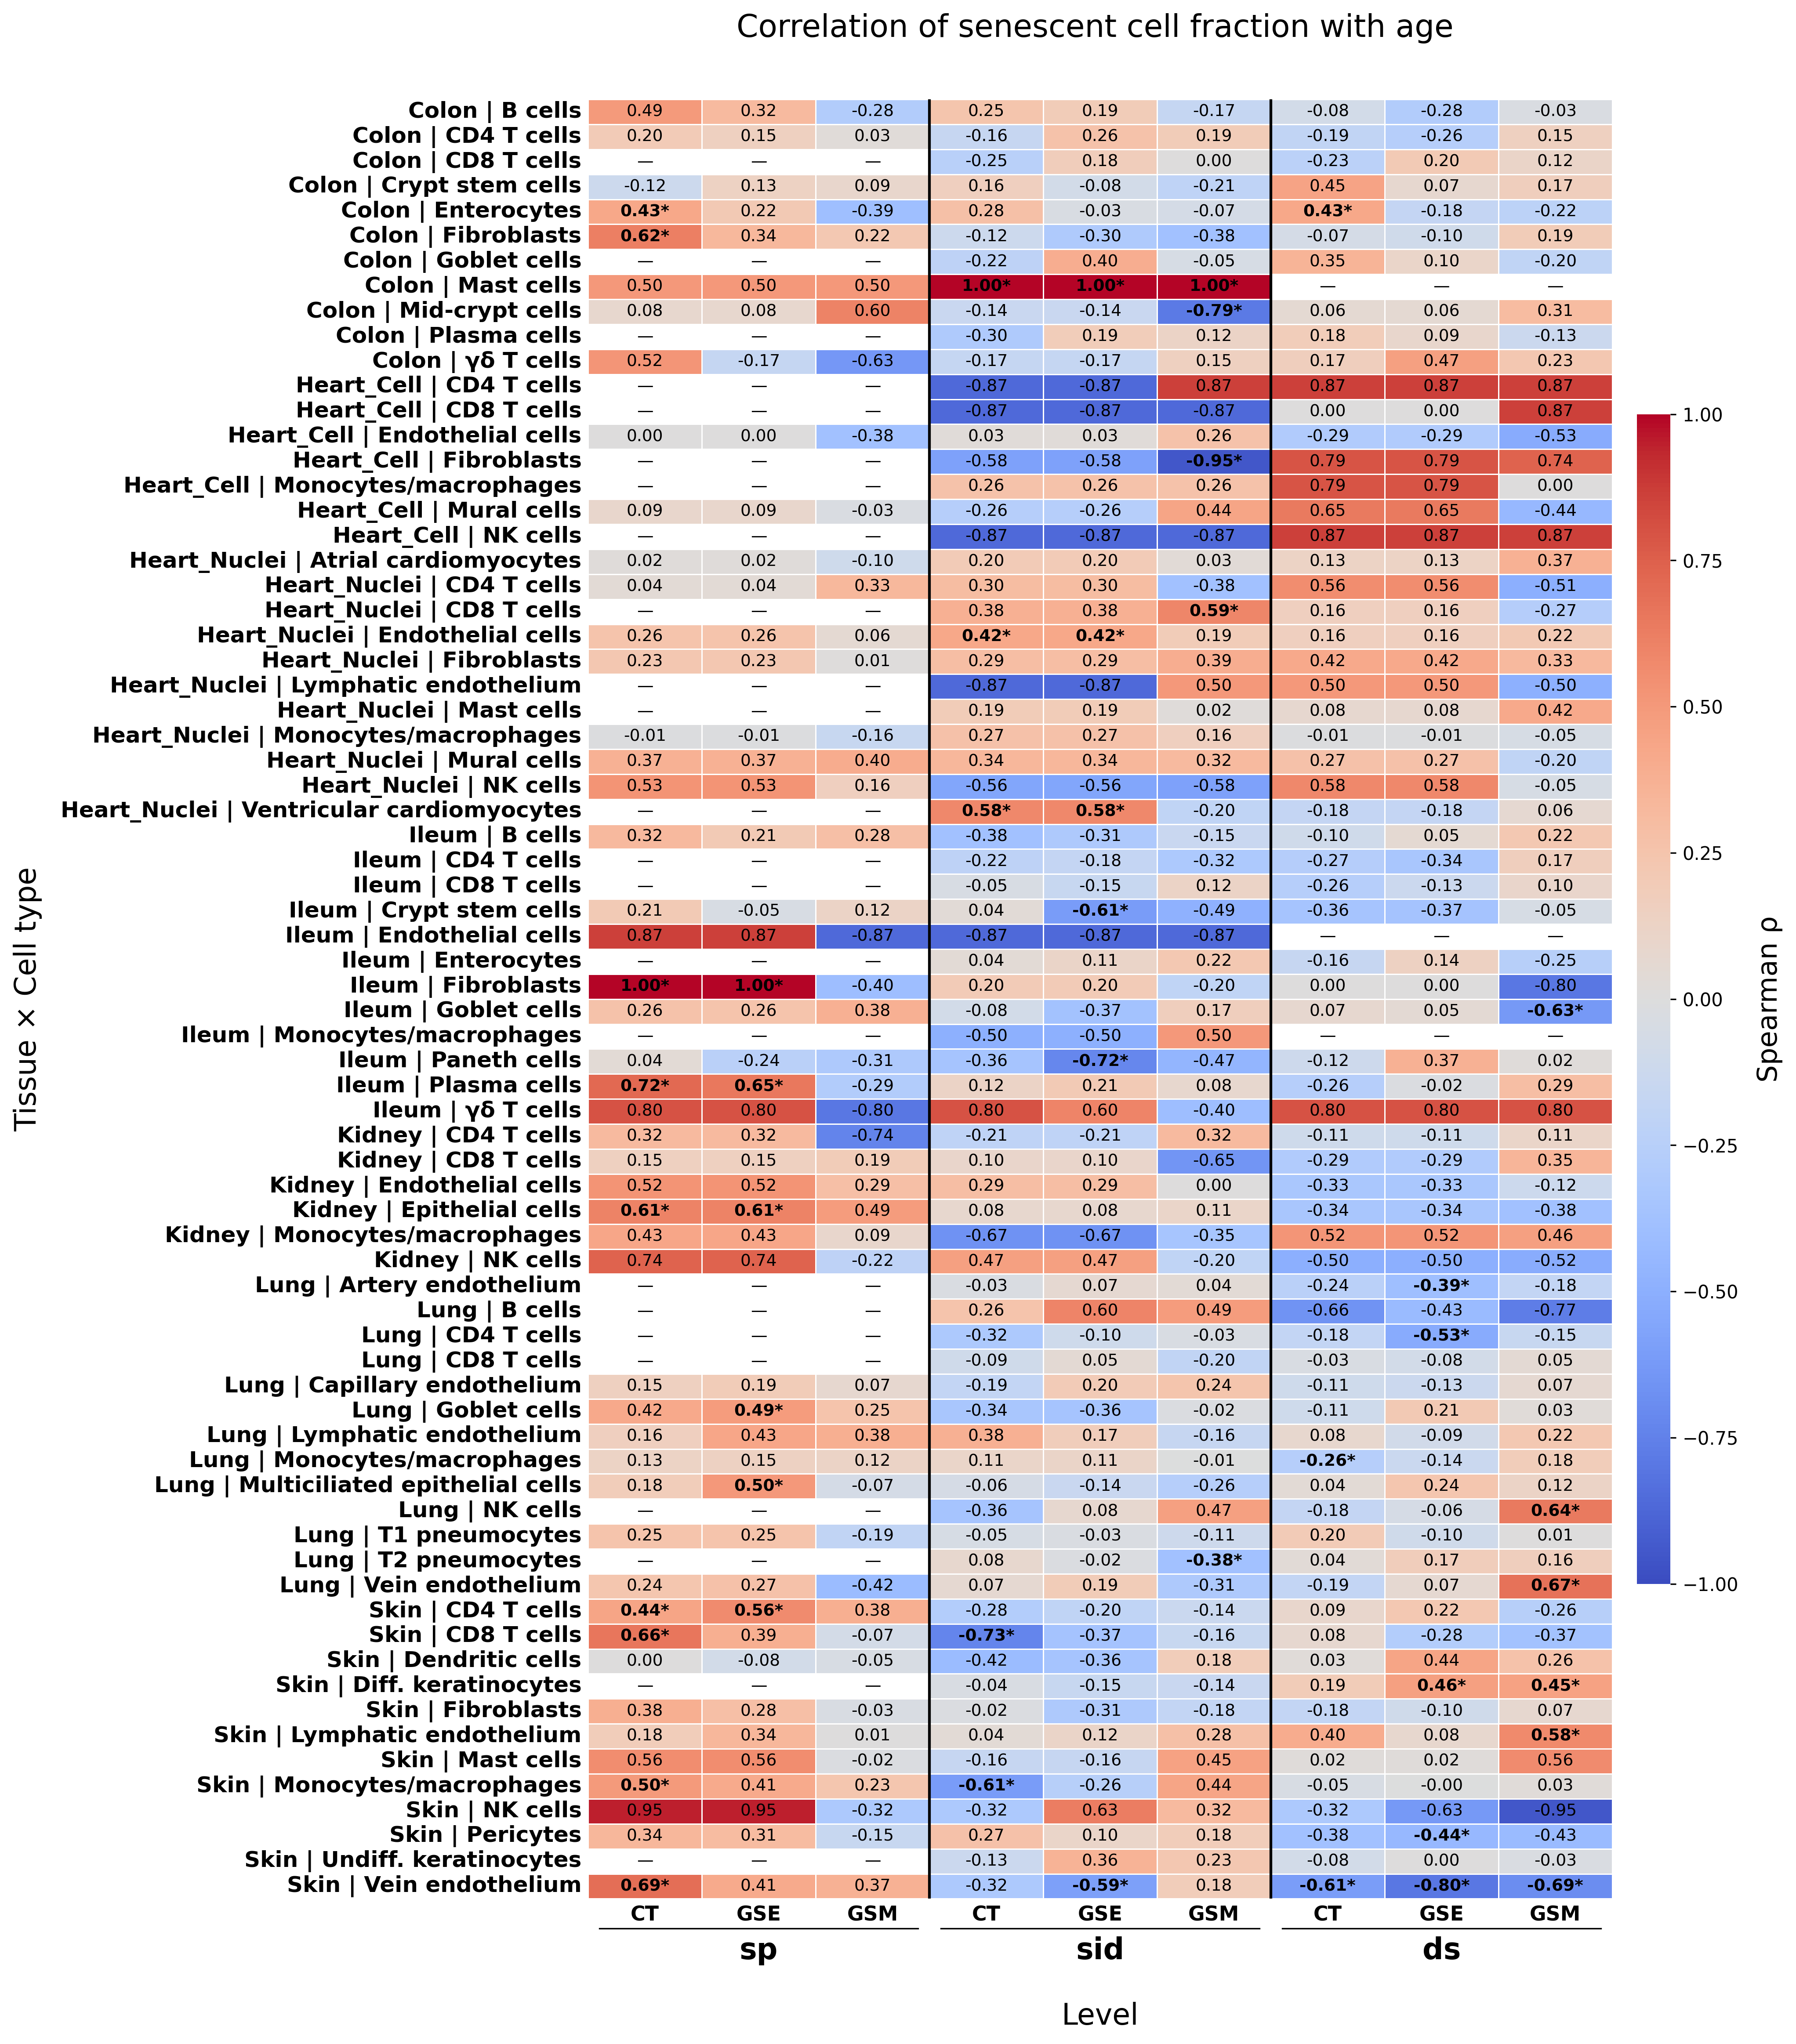

In [37]:
plot_df = corr_df.copy()

# Данные

# Строка для heatmap
plot_df["Tissue_cell_type"] = plot_df["Tissue_global"] + " | " + plot_df["cell_type"]
# Названия колонок
plot_df["Method_Level"] = plot_df["method"] + " | " + plot_df["level"].str.upper()

# Pivot для rho
heatmap_rho = plot_df.pivot(
    index="Tissue_cell_type", columns="Method_Level", values="spearman_r"
)

# Pivot для FDR
heatmap_fdr = plot_df.pivot(
    index="Tissue_cell_type", columns="Method_Level", values="spearman_p"
)

# Порядок колонок
method_order = ["sp", "sid", "ds"]
level_order = ["CT", "GSE", "GSM"]

column_order = [
    f"{method} | {level}" for method in method_order for level in level_order
]

# Оставляем только существующие
column_order = [col for col in column_order if col in heatmap_rho.columns]

heatmap_rho = heatmap_rho[column_order]
heatmap_fdr = heatmap_fdr[column_order]


# Размеры heatmap
n_rows, n_cols = heatmap_rho.shape

# Plot
fig, ax = plt.subplots(figsize=(13, max(8, len(heatmap_rho) * 0.24)), dpi=300)

sns.heatmap(
    heatmap_rho,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    # Значения теперь рисуем вручную
    annot=False,
    linewidths=0.3,
    linecolor="white",
    cbar_kws={
        "label": "Spearman ρ",
        "shrink": 0.65,
        "aspect": 35,
        "pad": 0.02,
    },
    ax=ax,
)


# Значения внутри heatmap
for row in range(n_rows):
    for col in range(n_cols):
        rho = heatmap_rho.iloc[row, col]
        fdr = heatmap_fdr.iloc[row, col]

        # Отсутствующее значение
        if pd.isna(rho):
            ax.text(
                col + 0.5,
                row + 0.5,
                "—",
                ha="center",
                va="center",
                fontsize=9,
                color="black",
            )

        # Значение
        else:
            # Статистическая значимость
            significant = not pd.isna(fdr) and fdr < 0.05

            if significant:
                text = f"{rho:.2f}*"
                fontweight = "bold"
            else:
                text = f"{rho:.2f}"
                fontweight = "normal"

            ax.text(
                col + 0.5,
                row + 0.5,
                text,
                ha="center",
                va="center",
                fontsize=9,
                fontweight=fontweight,
                color="black",
            )

# Разделительные линии между методами
for x in [3, 6]:
    if x < n_cols:
        ax.axvline(x, color="black", linewidth=1.5, zorder=10)

# Подписи осей
ax.set_xlabel(
    "Level",
    fontsize=16,
    labelpad=42,
)
ax.set_ylabel(
    "Tissue × Cell type",
    fontsize=16,
    labelpad=10,
)
ax.set_title(
    "Correlation of senescent cell fraction with age \n",
    fontsize=17,
    pad=15,
)

# X-axis: только уровень
level_labels = [col.split(" | ")[1] for col in heatmap_rho.columns]
ax.set_xticklabels(
    level_labels,
    fontsize=11,
    fontweight="semibold",
    rotation=0,
)
ax.tick_params(
    axis="x",
    length=0,
)

# Y-axis
ax.tick_params(
    axis="y",
    labelsize=12,
    length=0,
)

for label in ax.get_yticklabels():
    label.set_fontweight("semibold")

# Названия методов под группами
method_centers = []
method_labels = []

for method in method_order:
    method_columns = [
        col for col in heatmap_rho.columns if col.startswith(f"{method} |")
    ]
    if len(method_columns) == 0:
        continue

    first_col = heatmap_rho.columns.get_loc(method_columns[0])
    last_col = heatmap_rho.columns.get_loc(method_columns[-1])
    center = (first_col + last_col + 1) / 2

    method_centers.append(center)
    method_labels.append(method)

# Горизонтальные линии под группами уровней
line_y = n_rows + 1.18
for method in method_order:
    method_columns = [
        col for col in heatmap_rho.columns if col.startswith(f"{method} |")
    ]

    if len(method_columns) == 0:
        continue

    first_col = heatmap_rho.columns.get_loc(method_columns[0])
    last_col = heatmap_rho.columns.get_loc(method_columns[-1])

    ax.plot(
        [first_col + 0.1, last_col + 0.9],
        [line_y, line_y],
        color="black",
        linewidth=0.8,
        clip_on=False,
    )

# Подписи методов
for center, method in zip(method_centers, method_labels):
    ax.text(
        center,
        n_rows + 2.08,
        method,
        ha="center",
        va="center",
        fontsize=16,
        fontweight="semibold",
        clip_on=False,
    )

# Colorbar
cbar = ax.collections[0].colorbar
cbar.ax.tick_params(
    labelsize=10,
    length=3,
)
cbar.set_label(
    "Spearman ρ",
    fontsize=15,
    labelpad=10,
)

# Размеры полей
plt.subplots_adjust(
    bottom=0.15,
    top=0.94,
    left=0.20,
    right=0.92,
)
# plt.savefig("heatmap_spearman_rho.png",dpi=300,bbox_inches="tight")

plt.show()

In [40]:
obs = pd.read_csv(".././5.1_3_obs_all_scores_and_bins.csv", index_col=0)
obs.head()

/tmp/ipykernel_1063956/1100530406.py:1: DtypeWarning: Columns (21,24,27) have mixed types. Specify dtype option on import or set low_memory=False.
  obs = pd.read_csv(".././5.1_3_obs_all_scores_and_bins.csv", index_col=0)


,GSE_id,GSM_id,Age,Tissue_global,cell_type_final,Age_bin,cell_type,n_expr_genes,sp,RecSID,sid,ds,fridman,cellage,senmayo,sp_centered_median,sid_centered_median,ds_centered_median,sp_is_sen_median_ct,sid_is_sen_median_ct,ds_is_sen_median_ct,sp_is_sen_median_gse,sid_is_sen_median_gse,ds_is_sen_median_gse,sp_is_sen_median_gsm,sid_is_sen_median_gsm,ds_is_sen_median_gsm
AAACCTGAGGCCGAAT-1-GSM3758115,GSE130973,GSM3758115,25.0,Skin,Fibroblast,21.0,Fibroblasts,950.0,3.951097,SID3,0.773698,0.156639,0.222860,0.048563,0.124413,1.170299,0.475860,-0.666287,False,True,False,False,True,False,False,True,False
AAACCTGAGTTAAGTG-1-GSM3758115,GSE130973,GSM3758115,25.0,Skin,CD8T,21.0,CD8 T cells,1247.0,0.114196,SID3,0.607294,0.125290,0.096653,0.047017,0.039243,-0.033471,-0.119954,-0.800847,False,False,False,False,False,False,False,False,False
AAACCTGGTCTTCTCG-1-GSM3758115,GSE130973,GSM3758115,25.0,Skin,VE,21.0,Vein endothelium,724.0,0.151354,SID3,0.877589,0.529626,0.070124,0.068919,0.055252,-0.276956,0.012434,-0.132633,False,False,False,False,False,False,False,False,False
AAACCTGGTGCAACTT-1-GSM3758115,GSE130973,GSM3758115,25.0,Skin,DC,21.0,Dendritic cells,1888.0,1.127572,SID3,0.754094,3.609708,0.071895,0.055063,0.062890,-0.232897,0.096031,1.156324,False,False,False,False,False,False,False,False,False
AAACCTGTCAGCGACC-1-GSM3758115,GSE130973,GSM3758115,25.0,Skin,CD4T,21.0,CD4 T cells,721.0,0.178643,SID3,0.518898,-0.213985,0.029474,0.056690,0.077574,0.054865,-0.185136,-1.520335,False,False,False,False,False,False,False,False,False


In [41]:
obs.columns

Index(['GSE_id', 'GSM_id', 'Age', 'Tissue_global', 'cell_type_final',
       'Age_bin', 'cell_type', 'n_expr_genes', 'sp', 'RecSID', 'sid', 'ds',
       'fridman', 'cellage', 'senmayo', 'sp_centered_median',
       'sid_centered_median', 'ds_centered_median', 'sp_is_sen_median_ct',
       'sid_is_sen_median_ct', 'ds_is_sen_median_ct', 'sp_is_sen_median_gse',
       'sid_is_sen_median_gse', 'ds_is_sen_median_gse', 'sp_is_sen_median_gsm',
       'sid_is_sen_median_gsm', 'ds_is_sen_median_gsm'],
      dtype='object')

In [34]:
corr_df.head()

,Tissue_global,cell_type,pearson_r,pearson_p,spearman_r,spearman_p,n_donors,pearson_fdr,spearman_fdr,method,level
0,Colon,B cells,0.526300,0.036238,0.493373,0.052132,16,0.119057,0.217114,sp,ct
1,Colon,CD4 T cells,0.209416,0.337556,0.202820,0.353333,23,0.475815,0.578328,sp,ct
2,Colon,Crypt stem cells,0.036195,0.883049,-0.121266,0.620931,19,0.901837,0.805532,sp,ct
3,Colon,Enterocytes,0.437118,0.032687,0.426116,0.037870,24,0.119057,0.217114,sp,ct
4,Colon,Fibroblasts,0.554372,0.011194,0.623730,0.003295,20,0.094523,0.039545,sp,ct


In [42]:
from scipy.stats import shapiro

# Словарь для хранения итоговых результатов по каждой колонке
final_stats = {}

for method in ["sp", "sid", "ds"]:
    for level in ["ct", "gse", "gsm"]:
        column = f"{method}_is_sen_median_{level}"
        valid = obs[column].notna()
        obs_filt = obs.loc[valid].copy()

        if obs_filt.empty:
            print(f"Колонка {column} пуста после фильтрации. Пропускаем.")
            continue

        # 1. Считаем % True для каждого GSM_id внутри ['Tissue_global', 'cell_type']
        # .mean() от булевой колонки как раз возвращает долю (от 0.0 до 1.0)
        grouped_gsm = (
            obs_filt.groupby(["Tissue_global", "cell_type", "GSM_id"], observed=True)[
                column
            ]
            .mean()
            .reset_index(name="pct_true")
        )

        # Счётчики для текущей колонки
        normal_count = 0
        not_normal_count = 0
        insufficient_data = 0

        # 2. Группируем по ['Tissue_global', 'cell_type'] для проверки нормальности
        main_groups = grouped_gsm.groupby(["Tissue_global", "cell_type"], observed=True)

        for name, group_df in main_groups:
            values = group_df["pct_true"]

            # Тест Шапиро-Уилка требует минимум 3 наблюдения
            if len(values) < 3:
                insufficient_data += 1
                continue

            # Если все значения одинаковы (например, везде 0% или 100%),
            # тест Шапиро-Уилка выдаст ошибку/предупреждение, так как дисперсия равна 0.
            if values.nunique() == 1:
                not_normal_count += 1
                continue

            # Проводим тест на нормальность
            stat, p_value = shapiro(values)

            # Уровень значимости альфа = 0.05
            if p_value > 0.05:
                normal_count += 1  # Принимаем H0: распределение нормальное
            else:
                not_normal_count += 1  # Отклоняем H0: распределение НЕ нормальное

        # Сохраняем результаты
        final_stats[column] = {
            "Нормальное": normal_count,
            "Не нормальное": not_normal_count,
            "Мало данных (<3 GSM)": insufficient_data,
        }

# 3. Выводим красивую результирующую таблицу
stats_df = pd.DataFrame(final_stats).T
print("\nСтатистика распределения по колонкам:")
print(stats_df)



Статистика распределения по колонкам:
                       Нормальное  Не нормальное  Мало данных (<3 GSM)
sp_is_sen_median_ct            25             23                     0
sp_is_sen_median_gse           30             18                     0
sp_is_sen_median_gsm           30             18                     0
sid_is_sen_median_ct           48             24                     0
sid_is_sen_median_gse          46             26                     0
sid_is_sen_median_gsm          50             22                     0
ds_is_sen_median_ct            52             17                     0
ds_is_sen_median_gse           52             17                     0
ds_is_sen_median_gsm           46             23                     0


/tmp/ipykernel_228197/3832689037.py:27: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:black'` for the same effect.

  sns.stripplot(
/tmp/ipykernel_228197/3832689037.py:53: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(["Cell type (CT)", "Study / GSE", "Sample / GSM"])


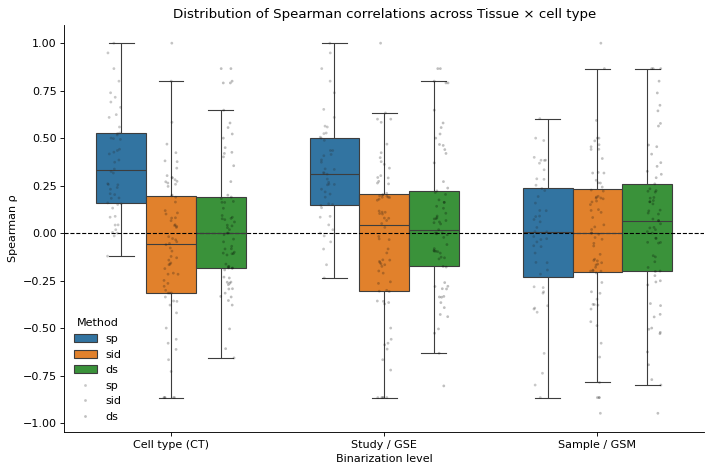

In [ ]:
"""Boxplot: распределение Spearman ρ"""

plot_df = corr_df.copy()

# Порядок категорий
plot_df["level"] = pd.Categorical(
    plot_df["level"], categories=["ct", "gse", "gsm"], ordered=True
)
plot_df["method"] = pd.Categorical(
    plot_df["method"], categories=["sp", "sid", "ds"], ordered=True
)


fig, ax = plt.subplots(figsize=(9, 6))
sns.boxplot(
    data=plot_df,
    x="level",
    y="spearman_r",
    hue="method",
    order=["ct", "gse", "gsm"],
    hue_order=["sp", "sid", "ds"],
    width=0.7,
    showfliers=False,
    ax=ax,
)

sns.stripplot(
    data=plot_df,
    x="level",
    y="spearman_r",
    hue="method",
    order=["ct", "gse", "gsm"],
    hue_order=["sp", "sid", "ds"],
    dodge=True,
    alpha=0.25,
    size=2.5,
    color="black",
    ax=ax,
)

# Убираем дублирующуюся легенду
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles[:3], labels[:3], title="Method", frameon=False)

# Нулевая корреляция
ax.axhline(0, linestyle="--", linewidth=1, color="black")

ax.set_xlabel("Binarization level")
ax.set_ylabel("Spearman ρ")
ax.set_title("Distribution of Spearman correlations across Tissue × cell type")

# Более понятные подписи
ax.set_xticklabels(["Cell type (CT)", "Study / GSE", "Sample / GSM"])

ax.legend(title="Method", frameon=False)

sns.despine()

plt.tight_layout()

# plt.savefig(
#     "boxplot_spearman_rho.png",
#     dpi=300,
#     bbox_inches="tight"
# )

plt.show()

# “The whiskers extend from the box to the farthest data point lying within 1.5x the IQR from the box.”
# т.е. усы — это не сам интервал Q1 ± 1.5 IQR, а диапазон до фактически наблюдаемых крайних точек,
# которые попадают внутрь этого порога. Это небольшая, но статистически важная разница.

# Центральная линия внутри box	медиана, 50-й перцентиль
# Нижняя граница box	Q1, 25-й перцентиль
# Верхняя граница box	Q3, 75-й перцентиль
# Высота box	IQR = Q3 − Q1
# Нижний whisker	минимальное наблюдение в пределах Q1 − 1.5×IQR
# Верхний whisker	максимальное наблюдение в пределах Q3 + 1.5×IQR
# Точки дальше whiskers	outliers
# showfliers=False	outliers на графике скрыты